<a href="https://colab.research.google.com/github/aayushcs007/BIS_LAB-1BF24CS007-/blob/main/pso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 1: Best Fitness = 415.6407
Iteration 2: Best Fitness = 415.6407
Iteration 3: Best Fitness = 401.7744
Iteration 4: Best Fitness = 302.1068
Iteration 5: Best Fitness = 302.1068
Iteration 6: Best Fitness = 302.1068
Iteration 7: Best Fitness = 275.6473
Iteration 8: Best Fitness = 263.7376
Iteration 9: Best Fitness = 263.7376
Iteration 10: Best Fitness = 255.2957
Iteration 11: Best Fitness = 255.2957
Iteration 12: Best Fitness = 255.2957
Iteration 13: Best Fitness = 246.7692
Iteration 14: Best Fitness = 246.7692
Iteration 15: Best Fitness = 242.4907
Iteration 16: Best Fitness = 241.6563
Iteration 17: Best Fitness = 241.6563
Iteration 18: Best Fitness = 241.6563
Iteration 19: Best Fitness = 241.2219
Iteration 20: Best Fitness = 241.2219
Iteration 21: Best Fitness = 239.4459
Iteration 22: Best Fitness = 238.5336
Iteration 23: Best Fitness = 238.5336
Iteration 24: Best Fitness = 238.5336
Iteration 25: Best Fitness = 238.5057
Iteration 26: Best Fitness = 238.5057
Iteration 27: Best Fi

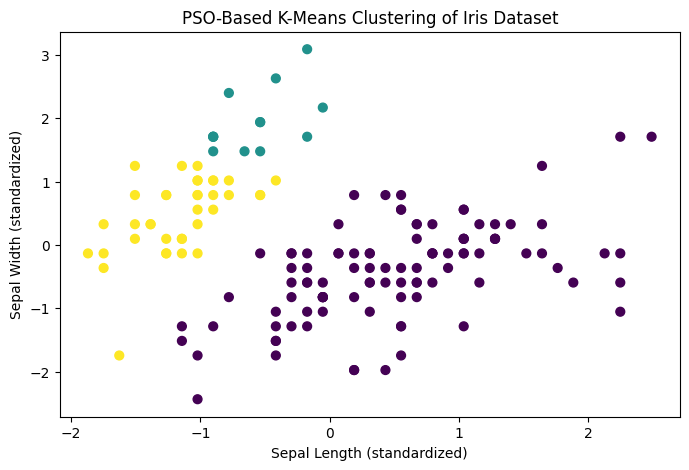

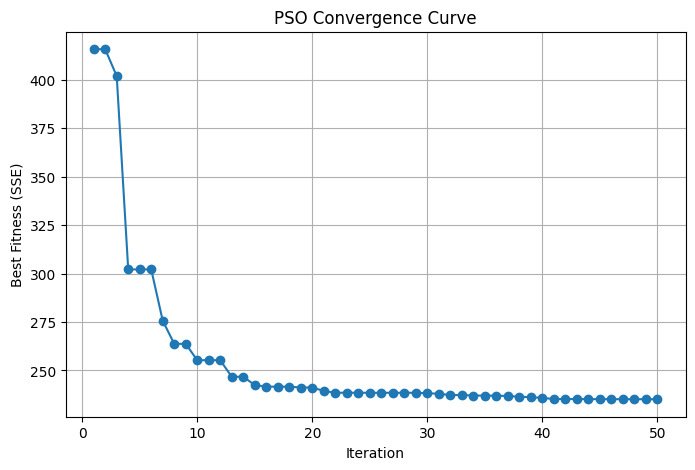

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score


# Step 1: Load the Iris dataset
iris = load_iris()
X = iris.data

# Normalize the data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 2: Initialize PSO parameters
K = 3
n_particles = 20
max_iter = 50

w = 0.7
c1 = 1.5
c2 = 1.5

n_samples, n_features = X.shape
dimension = K * n_features

lower_bound = X.min(axis=0)
upper_bound = X.max(axis=0)


# Step 3: Define fitness function
# Lower fitness means better clustering

def fitness(position):
    centers = position.reshape(K, n_features)

    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centers[np.newaxis, :, :],
        axis=2
    )

    minimum_distances = np.min(distances, axis=1)

    return np.sum(minimum_distances ** 2)


# Step 4: Initialize particles

particles = np.random.uniform(
    lower_bound.min(),
    upper_bound.max(),
    size=(n_particles, K, n_features)
)

velocities = np.random.uniform(
    -0.5, 0.5,
    size=(n_particles, K, n_features)
)

pbest = particles.copy()

pbest_fitness = np.array([
    fitness(p.reshape(-1))
    for p in particles
])

best_index = np.argmin(pbest_fitness)

gbest = pbest[best_index].copy()
gbest_fitness = pbest_fitness[best_index]

convergence = []


# Step 5: Perform PSO optimization

for iteration in range(max_iter):

    for i in range(n_particles):

        r1 = np.random.rand(K, n_features)
        r2 = np.random.rand(K, n_features)

        # Update velocity
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest[i] - particles[i])
            + c2 * r2 * (gbest - particles[i])
        )

        # Update position
        particles[i] += velocities[i]

        # Keep centers within data bounds
        particles[i] = np.clip(
            particles[i],
            lower_bound,
            upper_bound
        )

        # Calculate fitness
        current_fitness = fitness(particles[i].reshape(-1))

        # Update personal best
        if current_fitness < pbest_fitness[i]:
            pbest[i] = particles[i].copy()
            pbest_fitness[i] = current_fitness

        # Update global best
        if pbest_fitness[i] < gbest_fitness:
            gbest = pbest[i].copy()
            gbest_fitness = pbest_fitness[i]

    convergence.append(gbest_fitness)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Fitness = {gbest_fitness:.4f}"
    )


# Step 6: Apply K-means using PSO centers

pso_centers = gbest.copy()

pso_kmeans = KMeans(
    n_clusters=K,
    init=pso_centers,
    n_init=1,
    max_iter=300,
    random_state=42
)

pso_labels = pso_kmeans.fit_predict(X)


# Step 7: Apply ordinary K-means for comparison

normal_kmeans = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=10,
    random_state=42
)

normal_labels = normal_kmeans.fit_predict(X)


# Step 8: Evaluate clustering results

print("\n--- PSO-Based K-Means Results ---")

print("Best PSO Fitness:", round(gbest_fitness, 4))

print(
    "Silhouette Score:",
    round(silhouette_score(X, pso_labels), 4)
)

print(
    "Davies-Bouldin Index:",
    round(davies_bouldin_score(X, pso_labels), 4)
)

print("\n--- Ordinary K-Means Results ---")

print(
    "Silhouette Score:",
    round(silhouette_score(X, normal_labels), 4)
)

print(
    "Davies-Bouldin Index:",
    round(davies_bouldin_score(X, normal_labels), 4)
)


# Step 9: Visualize the clusters
# Use the first two features for a simple 2D plot

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=pso_labels,
    cmap="viridis",
    s=40
)

plt.xlabel("Sepal Length (standardized)")
plt.ylabel("Sepal Width (standardized)")
plt.title("PSO-Based K-Means Clustering of Iris Dataset")

plt.show()


# Step 10: Plot convergence

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iter + 1),
    convergence,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness (SSE)")
plt.title("PSO Convergence Curve")
plt.grid(True)

plt.show()